# 7. Panel detection and bubble reading order

Independent experiment: page → panel detection → panel order → bubble-to-panel assignment → bubble order. Use AppliedTaskByte (.venvAppliedTask). This notebook is unexecuted. No models, repositories or dependencies were downloaded or installed by Codex.

Provide these local files yourself:
- C:/MODELS/manga_panel_detector/manga_panel_detector_fp32.pt
- C:/MODELS/panel-order-estimator/order_estimator.py
- C:/MODELS/panel-order-estimator/manga109utils.py

The estimator imports manga109api through manga109utils; that package must already be installed. We use its bounding-box classes directly, without loading a Manga109 dataset or running main.py. Use an Ultralytics version supporting YOLO26. Existing speaker association and training notebooks are unchanged.


In [1]:
from pathlib import Path
import sys
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "models.json").is_file():
    raise FileNotFoundError("Start in 1pageTest or its 7_panel_reading_order folder.")
SEQUENCE_ID = "seq_71033fec4de494fc"
PAGE_NUMBER = 1
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
INTERMEDIATE = ROOT / "data/intermediate"
OUTPUT = ROOT / "data/panel_reading_order" / f"{SEQUENCE_ID}_page_{PAGE_NUMBER:02d}"
PANEL_MODEL = Path("C:/MODELS/manga_panel_detector/manga_panel_detector_fp32.pt")
ORDER_REPO = Path("C:/MODELS/panel-order-estimator")
CONFIDENCE = 0.25
IMAGE_SIZE = 640
SEPARATION_THRESHOLD = 0.25
INITIAL_CUT = "one-page"  # Use "two-page" for a true double-page image.
ROW_TOLERANCE = 40  # Pixels in the original page, for approximate bubble rows.

sys.path.insert(0, str(ROOT / "7_panel_reading_order"))
from reading_order_helpers import assign_bubbles_to_panels, order_bubbles_in_panel, flatten_panel_groups

page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def load_stage(name):
    payload = json.loads((INTERMEDIATE / name).read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to another page; regenerate its stage first.")
    return payload["records"]

def save_result(name, records):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    path = OUTPUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records}, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Saved:", path)

bubbles = load_stage("bubbles_clean.json")
ocr_results = load_stage("ocr_clean.json")
if {b["bubble_id"] for b in bubbles} != {r["bubble_id"] for r in ocr_results}:
    raise ValueError("Clean bubble/OCR IDs differ.")
print("Page:", PAGE)
print("Clean bubbles:", len(bubbles))


Page: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\TaskData\development\images\seq_71033fec4de494fc\01.png
Clean bubbles: 14


## Detect panels with your local YOLO checkpoint

Keep only class 0 (panel); class 1 is text and is not used here. PN IDs are arbitrary detection IDs, not reading positions. Stop if no valid panels are detected.


In [2]:
if not PANEL_MODEL.is_file():
    raise FileNotFoundError(f"Place the panel checkpoint at {PANEL_MODEL}. No download is attempted.")
from ultralytics import YOLO

detector = YOLO(str(PANEL_MODEL))
result = detector.predict(source=str(PAGE), conf=CONFIDENCE, imgsz=IMAGE_SIZE,
                          classes=[0], save=False, verbose=False)[0]
panels = []
for detection in result.boxes:
    if int(detection.cls.item()) != 0:
        continue
    x1, y1, x2, y2 = detection.xyxy[0].tolist()
    box = [max(0, int(x1)), max(0, int(y1)), min(page.width, int(x2)), min(page.height, int(y2))]
    if box[2] <= box[0] or box[3] <= box[1]:
        continue
    panels.append({"panel_id": f"PN{len(panels) + 1}", "box": box,
                   "confidence": float(detection.conf.item())})
if not panels:
    raise ValueError("No panels detected. Inspect the page/model or lower CONFIDENCE.")
save_result("panels.json", panels)
print(json.dumps(panels, indent=2))


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\panel_reading_order\seq_71033fec4de494fc_page_01\panels.json
[
  {
    "panel_id": "PN1",
    "box": [
      406,
      0,
      897,
      567
    ],
    "confidence": 0.9735336899757385
  },
  {
    "panel_id": "PN2",
    "box": [
      0,
      951,
      438,
      1499
    ],
    "confidence": 0.9600991606712341
  },
  {
    "panel_id": "PN3",
    "box": [
      56,
      622,
      491,
      894
    ],
    "confidence": 0.959194540977478
  },
  {
    "panel_id": "PN4",
    "box": [
      445,
      949,
      897,
      1148
    ],
    "confidence": 0.9542452692985535
  },
  {
    "panel_id": "PN5",
    "box": [
      444,
      1200,
      898,
      1390
    ],
    "confidence": 0.9452111124992371
  },
  {
    "panel_id": "PN6",
    "box": [
      500,
      621,
      790,
      892
    ],
    "confidence": 0.9419203400611877
  },
  {
    "panel_id": "PN7",
    "box": [
      59,
      110,
      396,
      568
    ],
  

## Estimate panel order using the local repository

The estimator separates panels top-to-bottom and right-to-left. It can return inseparable groups. Those groups remain flagged, and a deterministic top/right fallback provides a provisional order inside them. Inspect these cases before using the transcript.


In [3]:
for filename in ["order_estimator.py", "manga109utils.py"]:
    if not (ORDER_REPO / filename).is_file():
        raise FileNotFoundError(f"Place the full panel-order-estimator checkout at {ORDER_REPO}.")
sys.path.insert(0, str(ORDER_REPO))
import order_estimator
from manga109utils import BoundingBox

order_estimator.interception_ratio_threshold = SEPARATION_THRESHOLD
boxes = []
for panel in panels:
    x1, y1, x2, y2 = panel["box"]
    boxes.append(BoundingBox(xmin=x1, ymin=y1, xmax=x2, ymax=y2, id_=panel["panel_id"]))
estimator = order_estimator.BoxOrderEstimator(boxes, pagewidth=page.width,
                                             initial_cut_option=INITIAL_CUT)
panel_order, panel_groups, ambiguous_groups = flatten_panel_groups(estimator, panels)
save_result("panel_order.json", {"panel_order": panel_order, "panel_groups": panel_groups,
                               "ambiguous_groups": ambiguous_groups})
print("Panel order:", panel_order)
print("Inseparable groups requiring review:", ambiguous_groups)


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\panel_reading_order\seq_71033fec4de494fc_page_01\panel_order.json
Panel order: ['PN1', 'PN7', 'PN8', 'PN9', 'PN6', 'PN3', 'PN4', 'PN5', 'PN2']
Inseparable groups requiring review: []


## Assign and order bubbles

Use the panel containing each bubble center. If several panels contain it, choose the smallest. Missing panel assignments remain visible in unassigned_bubbles. Optional manual overrides can repair them after inspecting the preview. Bubbles are grouped into approximate rows, then read right-to-left within each row. This is a simple heuristic, not a learned bubble-order model.


In [4]:
PANEL_OVERRIDES = {}  # Example: {"B8": "PN2"}; None explicitly leaves a bubble unassigned.
assigned_bubbles = assign_bubbles_to_panels(bubbles, panels, PANEL_OVERRIDES)
panel_bubble_order = {}
for panel_id in panel_order:
    members = [b for b in assigned_bubbles if b["panel_id"] == panel_id]
    ordered = order_bubbles_in_panel(members, ROW_TOLERANCE)
    panel_bubble_order[panel_id] = [b["bubble_id"] for b in ordered]
bubble_order = [bubble_id for panel_id in panel_order for bubble_id in panel_bubble_order[panel_id]]
unassigned = [b["bubble_id"] for b in assigned_bubbles if b["panel_id"] is None]
settings = {"confidence": CONFIDENCE, "image_size": IMAGE_SIZE,
            "separation_threshold": SEPARATION_THRESHOLD, "initial_cut": INITIAL_CUT,
            "row_tolerance": ROW_TOLERANCE, "panel_overrides": PANEL_OVERRIDES}
save_result("bubble_panels.json", assigned_bubbles)
save_result("reading_order.json", {
    "sequence_id": SEQUENCE_ID, "page_number": PAGE_NUMBER,
    "panel_order": panel_order, "panel_groups": panel_groups,
    "ambiguous_panel_groups": ambiguous_groups,
    "panel_bubble_order": panel_bubble_order, "bubble_order": bubble_order,
    "unassigned_bubbles": unassigned,
    "needs_review": bool(unassigned or ambiguous_groups),
    "settings": settings,
    "inputs_sha256": {name: hashlib.sha256((INTERMEDIATE / name).read_bytes()).hexdigest()
                      for name in ["bubbles_clean.json", "ocr_clean.json"]},
    "detector_sha256": hashlib.sha256(PANEL_MODEL.read_bytes()).hexdigest(),
    "estimator_sha256": {name: hashlib.sha256((ORDER_REPO / name).read_bytes()).hexdigest()
                         for name in ["order_estimator.py", "manga109utils.py"]},
})
print("Bubble order:", bubble_order)
print("Unassigned bubbles:", unassigned)


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\panel_reading_order\seq_71033fec4de494fc_page_01\bubble_panels.json
Saved: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\panel_reading_order\seq_71033fec4de494fc_page_01\reading_order.json
Bubble order: ['B1', 'B2', 'B3', 'B4', 'B6', 'B8', 'B7', 'B9', 'B12', 'B13', 'B14', 'B15', 'B10', 'B11']
Unassigned bubbles: []


## Inspect the panel and bubble reading-order preview

Green labels show PN ID and reading position; blue labels show bubble ID and position. Orange bubbles are unassigned. Inseparable panels are marked REVIEW.


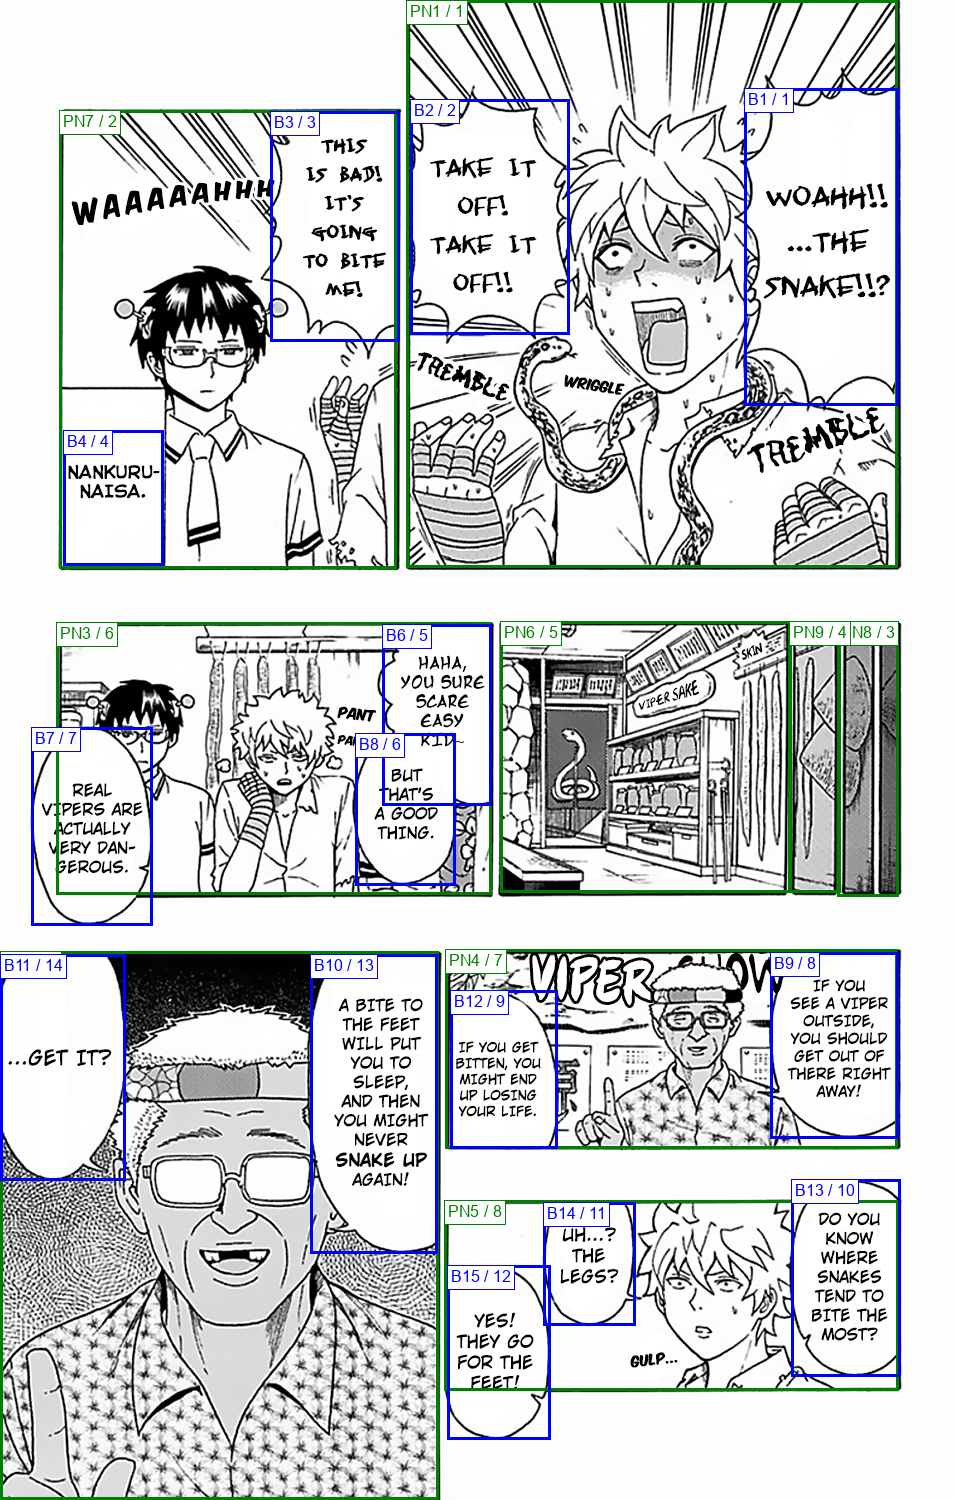

In [5]:
preview = page.copy()
draw = ImageDraw.Draw(preview)
font_path = Path("C:/Windows/Fonts/arial.ttf")
font_size = max(16, page.width // 60)
font = ImageFont.truetype(str(font_path), font_size) if font_path.is_file() else ImageFont.load_default(size=font_size)

def mark(box, label, color):
    x1, y1, x2, y2 = box
    draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
    width = int(draw.textlength(label, font=font)) + 8
    height = font_size + 8
    x = max(0, min(x1, page.width - width))
    y = max(0, min(y1, page.height - height))
    draw.rectangle((x, y, x + width, y + height), fill="white", outline=color)
    draw.text((x + 4, y + 2), label, fill=color, font=font)

panel_positions = {panel_id: i for i, panel_id in enumerate(panel_order, 1)}
review_panels = {panel_id for group in ambiguous_groups for panel_id in group}
for panel in panels:
    panel_id = panel["panel_id"]
    label = f"{panel_id} / {panel_positions[panel_id]}"
    if panel_id in review_panels:
        label += " REVIEW"
    mark(panel["box"], label, "green")
bubble_positions = {bubble_id: i for i, bubble_id in enumerate(bubble_order, 1)}
for bubble in assigned_bubbles:
    bubble_id = bubble["bubble_id"]
    position = bubble_positions.get(bubble_id, "unassigned")
    mark(bubble["box"], f"{bubble_id} / {position}", "blue" if bubble_id in bubble_positions else "orange")
preview.save(OUTPUT / "reading_order_preview.png")
display(preview)


## Inspect OCR in reading order

Print ordered OCR first. Bubbles not assigned to panels are printed separately, so missing assignments are not silently dropped. Speaker association remains independent and can later be joined by the original B IDs; the shuffled training-sample IDs must not be joined directly to these IDs.


In [6]:
ocr_by_id = {record["bubble_id"]: record["text"] for record in ocr_results}
for position, bubble_id in enumerate(bubble_order, 1):
    print(f"{position:02d}. {bubble_id}: {ocr_by_id[bubble_id]}")
if unassigned:
    print("\nUnassigned; resolve before treating this as a complete transcript:")
    for bubble_id in unassigned:
        print(f"{bubble_id}: {ocr_by_id[bubble_id]}")


01. B1: 7 WOAHH!! ...THE SNAKE!!?
02. B2: TAKE IT OFF! TAKE IT OFF!! 口
03. B3: THIS I5 BAD! IT'S GOING TO BITE ME! O
04. B4: NANKURU- NAISA.
05. B6: HAHA, YOU SURE SCARE EASY KID~ BUT THAT'S
06. B8: VT KID BUT THAT'S A GOOD THING.
07. B7: REAL VIPERS ARE ACTLUALLY VERY DAN- GEROUS.
08. B9: IF YOU SEE A VIPER OUTSIDE, YOU SHOULD GET OUT OF THERE RIGHT AWAY!
09. B12: IF YOU GET BITTEN, YOU MIGHT END UP LOSING YOUR LIFE.
10. B13: DO YOU KNOW WHERE SNAKES TEND TO BITE THE MOST?
11. B14: UH...? THE LEGS?
12. B15: YES! THEY GO FOR THE FEET!
13. B10: A BITE TO THE FEET WILL PUT YOU TO SLEEP, AND THEN YOU MIGHT NEVER SNAKE UP AGAIN!
14. B11: ...GET IT?


Sources: [panel detector model card](https://huggingface.co/leoxs22/manga-panel-detector-yolo26n), [panel ordering repository](https://github.com/manga109/panel-order-estimator), [ordering API](https://github.com/manga109/panel-order-estimator/blob/main/order_estimator.py), [BoundingBox API](https://github.com/manga109/panel-order-estimator/blob/main/manga109utils.py).
